# Leave-one-out method (model_lopo)

Each row is held out exactly once. The dataset has no validated repeated-patient grouping, so this is **row-level LOOCV**, equivalent to leave-one-person-out only if each row is a different person. If multiple rows belong to one person, use grouped patient splits instead.

The fixed selector is RFE-CART top 20, chosen before this run. Each fold fits imputation, selection, Yeo-Johnson and standardization on the other 318 rows and exports the train/test transformed matrices under `data/processed/lopo/`. Models use those files; stacking refits transformations inside its inner CV as well.

Metrics are computed on pooled held-out predictions, not individual one-row folds. The single fixed seed controls estimators and inner stacking CV; the outer leave-one-out splits are deterministic. A one-run sample variance is undefined.

Final pickle models in **models/lopo/** are refitted on all rows for future predictions. Reported LOOCV metrics come from separate held-out fold models, never from the full-data refits.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Locate the project when launched from its root or notebooks directory.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "utils.py").is_file() and (p / "data/raw/dataset_gallstone").is_file())
sys.path.insert(0, str(ROOT))
from utils import (DEFAULT_SEEDS, DATASET_DIR, REPORT_METRICS, WORKFLOW_MODELS,
                   workflow_data, require_exports, prepare_holdout_exports,
                   load_pickle, continuous_columns, plot_evaluation)
sns.set_theme(style="whitegrid")
from utils import run_lopo_workflow
LOPO_SEED = 42
LOPO_SELECTION = "rfe"


## 1. Evaluate all models and the dummy benchmark

This is the longest notebook: 319 outer folds with additional internal fits for stacking. Transformed fold datasets are cached for later runs; model fitting is repeated. Full-data deployment models are saved once per model after evaluation.


In [2]:
metrics, summary = run_lopo_workflow(seed=LOPO_SEED, selection=LOPO_SELECTION)
display(metrics[["model", "rows", "accuracy", "roc_auc", "fnr", "recall", "FN", "TP", "FP", "TN"]])


/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

LOPO 1/319


/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weigh

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

...

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weigh

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: invalid value encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value 

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  w

,model,rows,accuracy,roc_auc,fnr,recall,FN,TP,FP,TN
0,logistic,319,0.783699,0.874401,0.180124,0.819876,29,132,40,118
1,random_forest,319,0.799373,0.856986,0.161491,0.838509,26,135,38,120
2,xgboost,319,0.761755,0.834853,0.192547,0.807453,31,130,45,113
3,lightgbm,319,0.786834,0.850932,0.167702,0.832298,27,134,41,117
4,stacking,319,0.786834,0.865202,0.198758,0.801242,32,129,36,122
5,dummy_prior,319,0.504702,0.000000,0.000000,1.000000,0,161,158,0


## 2. ROC curves and confusion matrices

Each ROC curve uses 319 held-out probabilities. The confusion matrix below is shown for the predeclared stacking model; it is not selected by looking at these test scores.

The training-prior dummy has a pooled LOOCV AUC of 0 on this dataset: omitting a positive row slightly reduces the training prior, while omitting a negative increases it. These fold-dependent constants reverse the pooled ranking despite containing no patient features. This is a LOOCV prior artifact, not learned discrimination. The diagonal ROC line is the fixed chance benchmark (AUC 0.5).


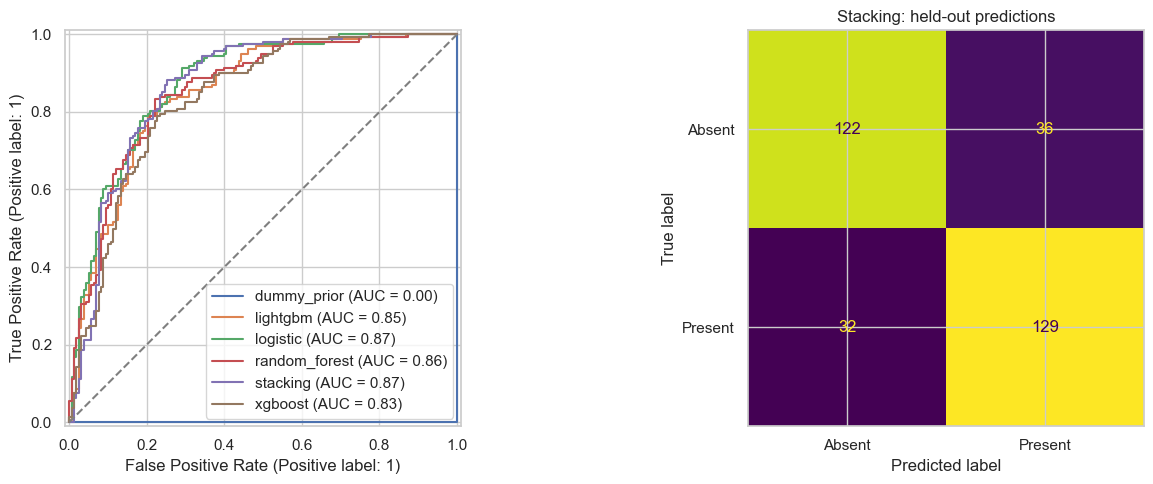

In [3]:
RESULTS = ROOT / "results" / "lopo"
predictions = pd.read_csv(RESULTS / "predictions.csv")
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, rows in predictions.groupby("model"):
    RocCurveDisplay.from_predictions(rows.actual_present, rows.probability_present, name=name, ax=axes[0])
axes[0].plot([0,1], [0,1], "--", color="gray")
stack_rows = predictions.loc[predictions.model == "stacking"]
ConfusionMatrixDisplay.from_predictions(stack_rows.actual_present, stack_rows.predicted_present,
    labels=[0,1], display_labels=["Absent", "Present"], ax=axes[1], colorbar=False)
axes[1].set_title("Stacking: held-out predictions")
fig.tight_layout()
fig.savefig(RESULTS / "roc_confusion.png", dpi=150, bbox_inches="tight")
plt.show()
